In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("Dataset.csv")

# ---- Step 1: Extract and clean country information ----
df["country"] = df["country"].str.strip()

# Check for placeholder values
print(df["country"].isin(["Not Given", "Unknown", ""]).sum())

# Keep only rows with a real country
df_country = df[df["country"] != "Not Given"].copy()
print(df_country.shape)          # expect (8503, 10)
print(df_country["country"].nunique())

# ---- Step 2: Calculate content count by country ----
country_counts = (
    df_country["country"]
    .value_counts()
    .reset_index()
)
country_counts.columns = ["country", "content_count"]

# Share of total content
country_counts["share_pct"] = (
    country_counts["content_count"] / country_counts["content_count"].sum() * 100
).round(2)

print(country_counts.head(10))

287
(8503, 10)
85
          country  content_count  share_pct
0   United States           3240      38.10
1           India           1057      12.43
2  United Kingdom            638       7.50
3        Pakistan            421       4.95
4          Canada            271       3.19
5           Japan            259       3.05
6     South Korea            214       2.52
7          France            213       2.50
8           Spain            182       2.14
9          Mexico            138       1.62


In [2]:
# Top 10 countries
top10 = country_counts.head(10).copy()
top10["rank"] = range(1, 11)
print(top10[["rank", "country", "content_count", "share_pct"]])

# How concentrated is the content?
print("Top 3 share :", country_counts["share_pct"].head(3).sum().round(2), "%")
print("Top 5 share :", country_counts["share_pct"].head(5).sum().round(2), "%")
print("Top 10 share:", country_counts["share_pct"].head(10).sum().round(2), "%")

# Movies vs TV Shows in the top 10
type_split = pd.crosstab(df_country["country"], df_country["type"])
top10_type = type_split.loc[top10["country"]]
top10_type["Total"] = top10_type.sum(axis=1)
top10_type["TV_Show_%"] = (top10_type["TV Show"] / top10_type["Total"] * 100).round(1)
print(top10_type)

   rank         country  content_count  share_pct
0     1   United States           3240      38.10
1     2           India           1057      12.43
2     3  United Kingdom            638       7.50
3     4        Pakistan            421       4.95
4     5          Canada            271       3.19
5     6           Japan            259       3.05
6     7     South Korea            214       2.52
7     8          France            213       2.50
8     9           Spain            182       2.14
9    10          Mexico            138       1.62
Top 3 share : 58.03 %
Top 5 share : 66.17 %
Top 10 share: 78.0 %
type            Movie  TV Show  Total  TV_Show_%
country                                         
United States    2395      845   3240       26.1
India             976       81   1057        7.7
United Kingdom    387      251    638       39.3
Pakistan           71      350    421       83.1
Canada            187       84    271       31.0
Japan              87      172    259     

C:\Users\kishore babu\AppData\Local\Temp\ipykernel_15764\1427750846.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="content_count", y="country", data=top10, palette="viridis")


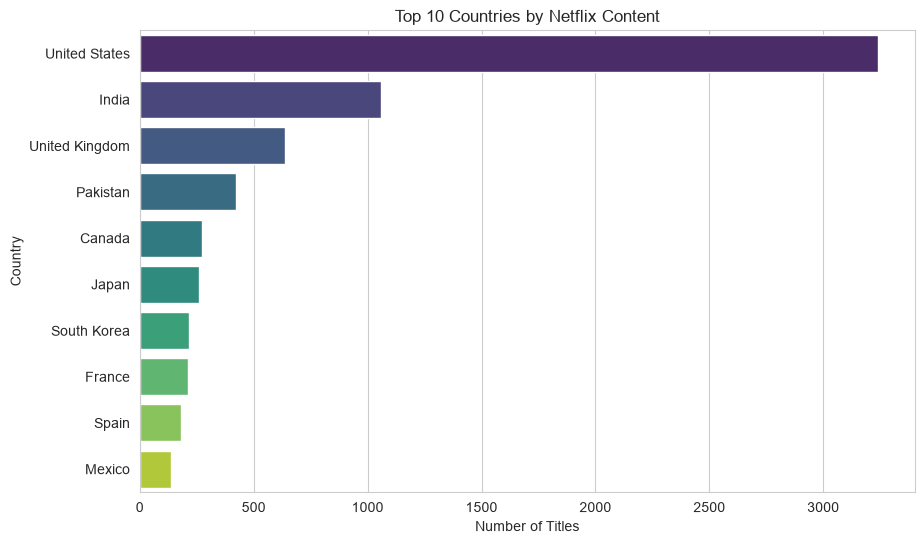

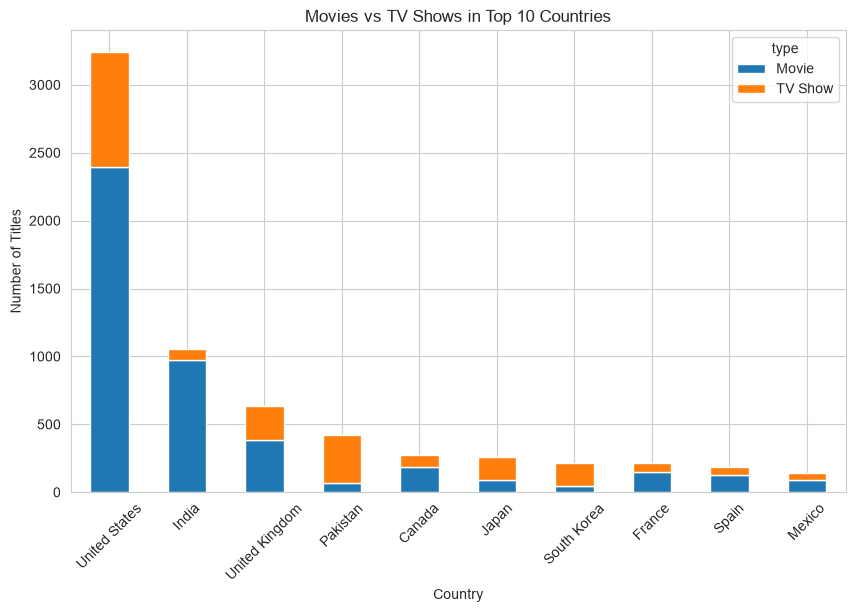

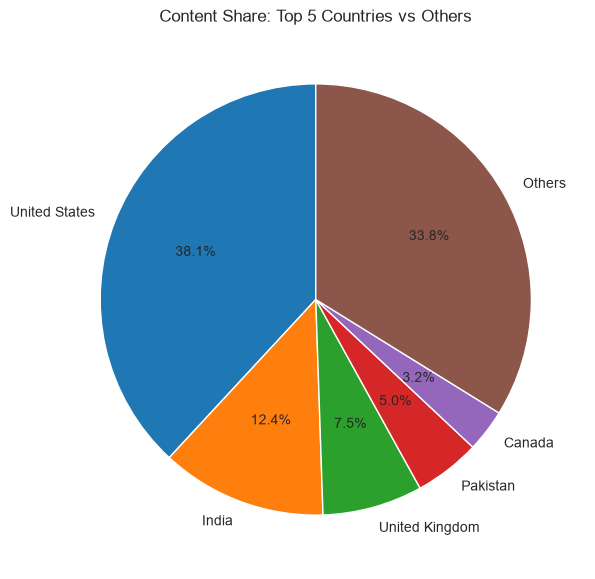

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# chart 1: top 10 countries by content count
plt.figure(figsize=(10, 6))
sns.barplot(x="content_count", y="country", data=top10, palette="viridis")
plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()


top10_type[["Movie", "TV Show"]].plot(kind="bar", stacked=True, figsize=(10, 6))
plt.title("Movies vs TV Shows in Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()
# chart 3: share of top 5 countries compared with the rest
top5 = country_counts.head(5)
others = country_counts["content_count"].iloc[5:].sum()

labels = list(top5["country"]) + ["Others"]
sizes = list(top5["content_count"]) + [others]

plt.figure(figsize=(7, 7))
plt.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=90)
plt.title("Content Share: Top 5 Countries vs Others")
plt.show()

# ranking table to save for the report
ranking = country_counts.head(10)
ranking.to_csv("country_ranking.csv", index=False)

In [7]:
# summary for the report
print("Total countries:", df_country["country"].nunique())
print("Titles with a known country:", len(df_country))
print("Top 10 cover", round(top10["share_pct"].sum(), 1), "% of titles")
print("Most TV heavy:", top10_type["TV_Show_%"].idxmax())
print("Most movie heavy:", top10_type["TV_Show_%"].idxmin())

Total countries: 85
Titles with a known country: 8503
Top 10 cover 78.0 % of titles
Most TV heavy: Pakistan
Most movie heavy: India
